# Базы данных. Основы `SQL`


**Что такое базы данных?**

В нашем случае мы будем работать с **реляционными** базами данных, которые представляют собой набор взаимосвязанных таблиц, которые по частям хранят определенный набор данных. Например, информацию о фильмах.


**Зачем какие-то базы, если есть CSV или JSON?**

Описание фильма имеет довольно сложную структуру и имеет разные составляющие (актеры, жанры, страны), поэтому довольно трудно это все поместить в таблицу или JSON так, чтобы это было еще и удобно для чтения. Чтобы, например, посчитать число комедий, мы должны прочитать каждую строку файла и посмотреть, а не комедия ли это, если да, то прибавить 1 к нашему счетчику. Это ничего, если у нас не так много данных (мегабайт), но довольно сложно, если у нас гигабайты данных. Для любого простого запроса нужно будет писать скрипт, который обработает файл и посчитает то, что нам нужно, а еще это будет работать очень долго.

**Ок, а что такое связанные таблицы?**

Чтобы таблицы могли совместно описывать какой-то сложный концепт, у нас должен быть способ хранить **ссылку на другую таблицу**, чтобы можно было соединить информацию, которая там находится. Например, можно указать ID фильма, чтобы знать, что эта информация относится к фильму, который имеет номер 123 в нашей базе. Это может также сократить место, которое будет занимать наша база. Вместо того, чтобы писать название фильма и его год для каждого актера + полные имена и информацию об актере каждый раз, когда мы хотим указать, что этот актер играет в этом фильме, мы просто можем записать пару ссылок: на фильм и на актера.

Допустим, у нас есть таблица со всей информацией про фильм:

| title       | year | name           |     |
|:-----------:|:----:|:--------------:|:---:|
| Ларри Краун | 2011 | Том Хэнкс      | ... |
| Ларри Краун | 2011 | Джулия Робертс | ... |
| Вам письмо  | 1998 | Том Хэнкс      | ... |
| Вам письмо  | 1998 | Мэг Райан      | ... |
| Красотка    | 1990 | Джулия Робертс | ... |
| Красотка    | 1990 | Ричард Гир     | ... |

Можно превратить ее в три таблицы:
1. актеры: *people*

| id | name           |     |
|:--:|:--------------:|:---:|
| 1  | Том Хэнкс      | ... |
| 2  | Джулия Робертс | ... |
| 3  | Мэг Райан      | ... |
| 4  | Ричард Гир     | ... |

2. фильмы: *films*

| id | title       | year |     |
|:--:|:-----------:|:----:|:---:|
| 1  | Ларри Краун | 2011 | ... |
| 2  | Вам письмо  | 1998 | ... |
| 3  | Красотка    | 1990 | ... |

3. таблица, которая связывает информацию, то есть отражает, что актер Х играл в фильме Y: *roles*

| film_id | person_id |
|:-------:|:---------:|
| 1       | 1         |
| 1       | 2         |
| 2       | 1         |
| 2       | 3         |
| 3       | 2         |
| 3       | 4         |

В виде таблицы это выглядело бы так:

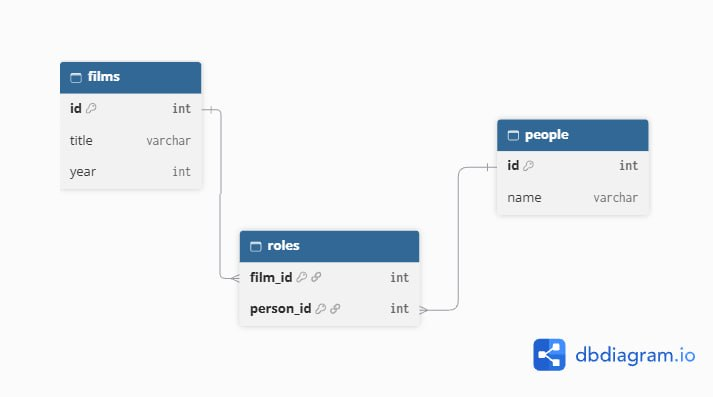

Хранить пару чисел намного легче, чем целые строчки текста и другой информации. Представьте, что у вас база IMDb или Кинопоиск, где тысячи фильмов и персон, каждый фильм надо связать с десятками или сотнями актеров.

К тому же, как и в случае функций в питоне, мы можем изменить информацию в одном месте, и она автоматически изменится везде. Например, не надо будет искать все вхождения фильма «Красотка», если мы хотим исправить неверно внесенный год.

## SQL и SQLite

**SQL (Structured Query Language)** – это особый язык для управления данными в БД. С помощью него можно добавлять, удалять, изменять и выбирать данные в таблицах. Любое обращение к базе данных называется запросом.

**SQL** – очень простой язык. Нам потребуется лишь:
- несколько команд для операций с данными (`CREATE`, `DELETE`, `DROP`, `SELECT`, `INSERT`, `UPDATE`)
- несколько команд-ограничителей для создания более точных запросов (`WHERE`, `IN`, `AND`, `OR`, `NOT`, `BETWEEN`, `LIKE`, `LIMIT`, `OFFSET`).

**NB!** Стоит обратить внимание на порядок слов-команд в запросах.

Для того, чтобы понять, что можно делать с данными в БД, есть специальный акроним – CRUD.

- **C**reate – создание таблиц, еще к этому можно отнести `INSERT` для вставки данных в созданную таблицу.
- **R**ead / **R**etrieve – получение информации.
- **U**pdate – обновление/изменение информации.
- **D**elete – удаление

Это основные действия с базами.

## Где можно посмотреть на базу и делать запросы?

База данных – это не текстовый формат, так что просто открыть его в блокноте и посмотреть, что внутри, не получится. Для работы с базами данных используются специальные программы – **системы управления базами данных (СУБД)**. Вы могли слышать о:
- MySQL
- SQLite
- PostgreSQL
- MariaDB
- и др.

Они в целом похожи, используют специальный язык запросов SQL. Но и немного отличаются, имеют свои плюсы и минусы, дополнительные функции, которые используются для более удобной работы. Вот [тут](https://www.capterra.com/resources/free-database-software/) есть неплохое описание плюсов и минусов всего вышеперечисленного.

Чаще всего используется связка сервер + клиент, то есть есть сервер, который управляет данными + клиент или визуальный интерфейс, который позволяет человеку обращаться к серверу с запросом на языке SQL.

Мы будем работать с **SQLite**, которая позволяет не создавать никаких серверов и работать с базой на любом компьютере.

Для работы с базами данных можно использовать десктоп-приложения или веб-версии. Например, можно работать [здесь](https://inloop.github.io/sqlite-viewer/).

О приложениях можно подробнее почитать в доп. блоке конспекта.



## IMDb

Мы будем работать с базой IMDb. Она сокращена, там отфильтрованы только фильмы, сериалы и мини-сериалы.

База [тут](https://yadi.sk/d/GOxdLhob7et7Hw?w=1). Если хотите просто потренироваться, то выбирайте файл [`imdb_very_small.db`](https://disk.yandex.ru/d/GOxdLhob7et7Hw/imdb_very_small.db?w=1).

Схема базы выглядит так:

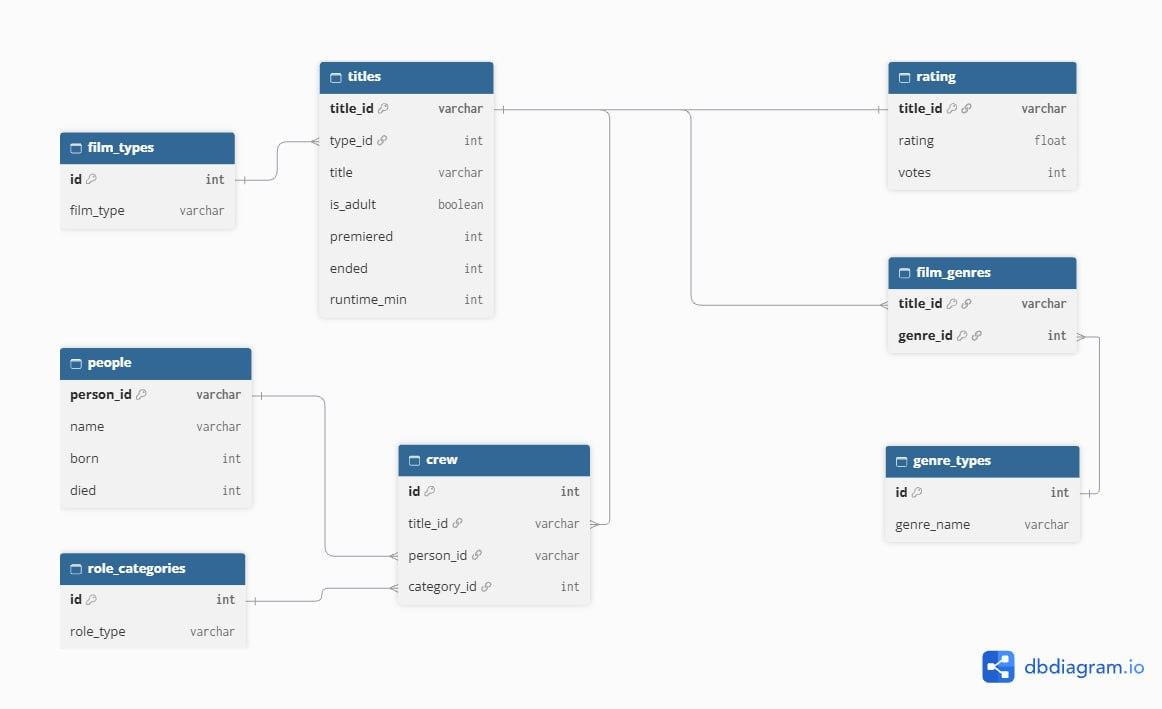

Версия с кодом – [здесь](https://dbdiagram.io/d/imdb_fikl_2026-6b0326c65cb51eed07670893).

На схеме можно увидеть, как связаны таблицы между собой.

Например, связи фильм – люди. У нас есть фильмы (*titles*) + люди (*people*). С помощью таблицы *crew* мы получаем информацию, что в фильме с таким ID участвует человек со вторым ID. В этой связи появляется еще один параметр − ID роли (например, 1 − actor, 2 − actress), эти номера и человеческие названия хранятся в таблице *role_categories*.

По этому же принципу хранятся жанры в привязке к фильму.

**SELECT**

Основное, что мы будем делать с базой − это получать данные с помощью запросов.

Попробуем вывести то, что находится в таблице про фильмы.

Первой идет команда ```SELECT```, затем ```*```, что значит все столбцы, затем ```FROM titles```, что значит из таблицы, которая называется *titles*.

``` sqlite
SELECT * FROM titles
```

Это довольно много всего, так как в таблице много строчек. В pandas мы могли вывести только верхушку с помощью `head`, здесь мы тоже можем сделать это с помощью `LIMIT`.

``` sqlite
SELECT * FROM titles LIMIT 10
```

Мы хотим получить первые 10 картин в базе, которые вышли не ранее 2019 года. Фильтровать данные в SQL можно с помощью ```WHERE```, после чего мы пишем условие. Запросы становятся больше, и принято делать переносы строк, чтобы логические части были видны.

``` sqlite
SELECT *
FROM titles
WHERE premiered >= 2019
LIMIT 10
```

Мы видим, что в столбце *type* находятся айди типов, но мы хотим, чтобы они показывались в человекочитаемом виде. Для этого мы соединяем таблицу с таблицей типов с помощью ```JOIN```. После команды следует название таблицы, затем ```ON``` и после этого то, по каким столбцам мы соединяем таблицы.

``` sqlite
SELECT *
FROM titles
    JOIN film_types ON titles.type = film_types.id
WHERE premiered >= 2019
LIMIT 50
```



Чтобы получить информацию о жанрах, мы должны использовать три таблицы: фильмы, жанры + таблица, их соединяющая.

Сначала мы присоединяем соединительную таблицу, а затем таблицу имен жанров.

```mysql
SELECT *
FROM titles
    JOIN film_genres ON titles.title_id = film_genres.title_id
    JOIN genre_types ON film_genres.genre_id = genre_types.id
WHERE premiered >= 2019
LIMIT 50
```

По присоединенным таблицам мы тоже можем фильтровать. Соединим условия через ```AND```.

``` sqlite
SELECT *
FROM titles
    JOIN film_genres ON titles.title_id = film_genres.title_id
    JOIN genre_types ON film_genres.genre_id = genre_types.id
WHERE premiered >= 2019 AND genre_name = "Comedy"
LIMIT 50
```

Мы можем отсортировать выдачу с помощью ```ORDER BY```. Например, найдем все фильмы, где играет Том Хэнкс, и отсортируем по убыванию года выхода.

``` sqlite
SELECT *
FROM titles
    JOIN crew ON titles.title_id = crew.title_id
    JOIN people ON crew.person_id = people.person_id
WHERE name = "Tom Hanks"
ORDER BY premiered DESC
```

Таблица довольно широкая, есть повторяющаяся информация, мы можем выбрать те столбцы, которые нам нужны. Если имена вдруг повторяются, то можно указать `таблица.столбец`.

``` sqlite
SELECT title, premiered
FROM titles
    JOIN crew ON titles.title_id = crew.title_id
    JOIN people ON crew.person_id = people.person_id
WHERE name = "Tom Hanks"
ORDER BY premiered DESC
```

Расчеты производятся быстро, но все равно мы видим задержку. Это происходит из-за того, что базе приходится все равно проходить по строчкам и проверять, всю ли информацию мы отфильтровали. Или для того, чтобы соединить таблицы.

Чтобы ускорить вычисления, можно сделать индексы. Это специальная структура данных в виде деревьев, которая хранит информацию о том, какие значения есть в столбце (или нескольких) и где.

Например, индексируется обычно первичный ключ. У таблицы есть уникальный ключ (первичный ключ) − ID, который позволяет однозначно определить запись. У нас такой может быть у фильмов, у людей, у жанров, у рейтинга − там ID уникальны.

``` sqlite
CREATE TABLE mytable (
    field1 text,
    field2 text,
    field3 integer,
    PRIMARY KEY (field1, field2)
);
```

Если мы находимся в десктоп-приложении, можно зайти в изменение таблицы и там установить столбцы как первичный ключ.

Теперь в интерфейсе они будут показываться с ключом.

Мы можем создавать индексы по любым, даже не уникальным столбцам, чтобы ускорить важные для нас запросы. Например, проиндексировать связующие таблицы, которые позволяют нам присоединить людей или жанры к главной таблице фильмов.

Попробуем запустить запрос:

``` sqlite
SELECT *
FROM titles
JOIN crew ON titles.title_id = crew.title_id
JOIN people ON crew.person_id = people.person_id
WHERE premiered >= 2019
LIMIT 50
```

``` sqlite
CREATE INDEX crew_title ON crew (title_id);
CREATE INDEX crew_person ON crew (person_id);
```

После этого еще раз повторим запрос – должно стать быстрее.

## Операции с данными

В БД можно не только выбирать данные, но и группировать, как, например, в pandas. И здесь это также называется ```GROUP BY```.

Например, мы можем найти фильмы, где играли несколько актеров, и сравнить максимальные, минимальные и средние рейтинги фильмов.


Для начала выберем фильмы, где играли Том Хэнкс, Джулия Робертс и Натали Портман. Мы можем использовать оператор ```IN```, чтобы задать список имен для поиска.

``` sqlite
SELECT name, title, premiered, rating
FROM titles
    JOIN crew ON titles.title_id = crew.title_id
    JOIN people ON crew.person_id = people.person_id
	JOIN rating ON titles.title_id = rating.title_id
WHERE name IN ("Tom Hanks", "Julia Roberts", "Natalie Portman")
```

Теперь сгруппируем по имени и вычислим наши показатели. Комментарии пишутся через ```--```.

``` sqlite
SELECT
    name,
    MAX(rating) as max_rating, -- максимум
    MIN(rating) as min_rating, -- минимум
    AVG(rating) as average_rating, -- среднее
    COUNT(titles.title_id) as n_films -- посчитаем число фильмов
FROM titles
    JOIN crew ON titles.title_id = crew.title_id
    JOIN people ON crew.person_id = people.person_id
    JOIN rating ON titles.title_id = rating.title_id
WHERE name IN ("Tom Hanks", "Julia Roberts", "Natalie Portman")
GROUP BY name
ORDER BY average_rating DESC
```

Среднее выглядит не очень красиво, очень много знаков после запятой, можно округлить.

``` sqlite
SELECT
    name,
    MAX(rating) as max_rating, -- максимум
    MIN(rating) as min_rating, -- минимум
    ROUND(AVG(rating), 2) as average_rating, -- среднее
    COUNT(titles.title_id) as n_films -- посчитаем число фильмов
FROM titles
    JOIN crew ON titles.title_id = crew.title_id
    JOIN people ON crew.person_id = people.person_id
    JOIN rating ON titles.title_id = rating.title_id
WHERE name IN ("Tom Hanks", "Julia Roberts", "Natalie Portman")
GROUP BY name
ORDER BY average_rating DESC
```

## Дополнительные ресурсы

Если хочется самостоятельно потренироваться с SQL, то для этого есть:

*   интерактивный тьюториал [SQLBolt](https://sqlbolt.com/) с теорией и заданиями.
*  [Яндекс-практикум](https://practicum.yandex.ru/promo/sql-trainer/)
* SQL-Academy (есть [тренажёр](https://sql-academy.org/ru/trainer), а есть [песочница](https://sql-academy.org/ru/sandbox), где можно потренироваться в свободном формате)
* [Детективная SQL-игра](https://mystery.knightlab.com/)



## Приложения: `DB Browser`

В качестве графического интерфейса можно использовать **DB Browser**, который позволяет посмотреть, что внутри базы, и делать запросы.

Его можно скачать и установить отсюда: https://sqlitebrowser.org/dl/

Откроем базу с помощью DB Browser.

Вот так будет выглядеть интерфейс:

<img src="https://github.com/hse-ling-python/seminars/blob/master/databases/img/interface.png?raw=1">

**CREATE**

На вкладке Database Structure мы видим все таблицы, которые есть в базе, и то, какие столбцы там имеются, если раскрыть содержание таблицы. Справа есть текст запроса, который позволит создать такую пустую таблицу. Можно скопировать этот текст, нажав «правой кнопкой мыши» (или эквивалент на вашем компьютере). Там будет меню copy create statement.

<img src="https://github.com/hse-ling-python/seminars/blob/master/databases/img/create.png?raw=1">